# COU 07506 Digital Signal Processing — Week 01: Lab 0 Setting Up the DSP Laboratory
Name: Maiga Yustard Kaare,
Registration_No: 240242426179,
Class: BEng24COE,  Group:, Date: 24/11/2026.

Git repository: https://github.com/mygayustard/COU07506-LABS.git

## Pre-lab
Three devices that contain DSP:
1. **Smartphone (voice call):** processes the speech signal from the microphone (filtering, echo cancellation, compression).
2. **Bluetooth earbuds / headphones:** processes the audio music signal (equalisation, noise cancellation).
3. **Smartwatch:** processes the optical (PPG) heart-rate signal from the wrist sensor.

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)
import scipy, matplotlib


In [11]:
import os
print(os.path.exists("my_voice.wav"))
from scipy.io import wavfile
fs, x = wavfile.read("my_voice.wav")
print(fs, "Hz,", len(x)/fs, "s,", len(x), "samples")

True
44100 Hz, 45.738027210884354 s, 2017047 samples


## Task 1.1 — Your first notebook

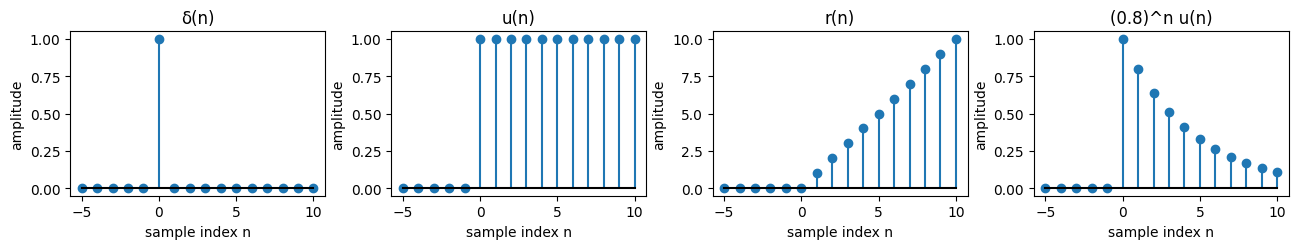

In [12]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)
step  = (n >= 0).astype(float)
ramp  = n * step
expo  = 0.8**n * step

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
                        ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title); ax.set_xlabel("sample index n"); ax.set_ylabel("amplitude")
plt.tight_layout(); plt.show()

## Task 1.2 — Change the parameters

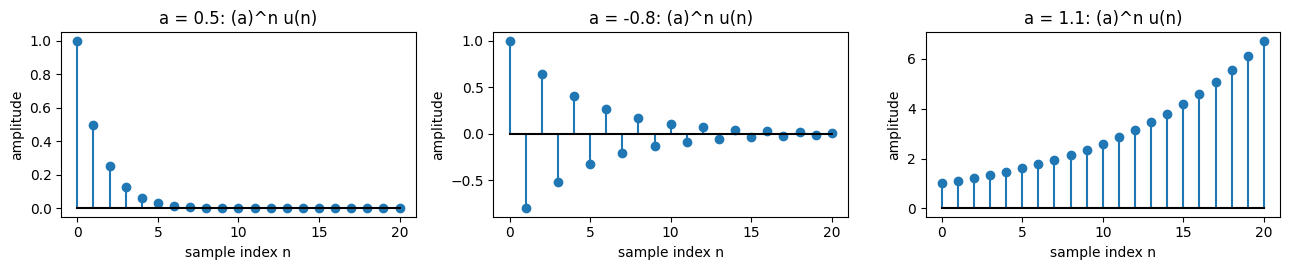

In [13]:

n = np.arange(0, 21)
fig, axes = plt.subplots(1, 3, figsize=(13, 2.8))
for ax, a in zip(axes, [0.5, -0.8, 1.1]):
    ax.stem(n, a**n, basefmt="k-")
    ax.set_title(f"a = {a}: (a)^n u(n)"); ax.set_xlabel("sample index n"); ax.set_ylabel("amplitude")
plt.tight_layout(); plt.show()

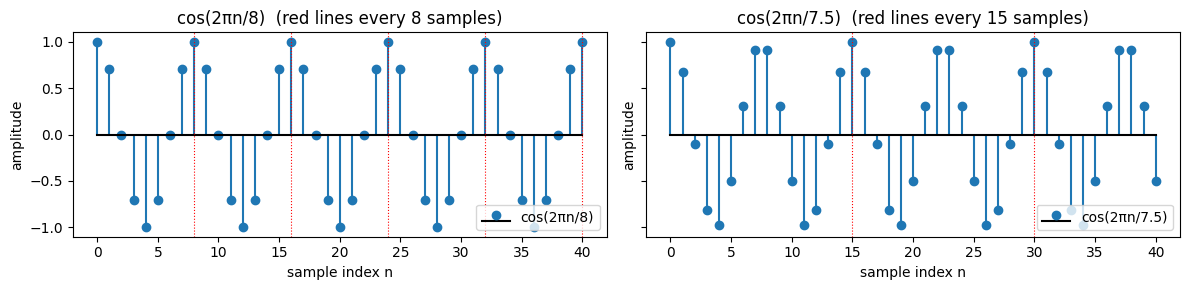

cos(2πn/8) repeats every 8 samples: True
cos(2πn/7.5) repeats every 8 samples: False
cos(2πn/7.5) repeats every 15 samples: True


In [14]:

n = np.arange(0, 41)
x8, x75 = np.cos(2*np.pi*n/8), np.cos(2*np.pi*n/7.5)
fig, axes = plt.subplots(1, 2, figsize=(12, 3), sharey=True)
for ax, x, name, N in zip(axes, [x8, x75], ["cos(2πn/8)", "cos(2πn/7.5)"], [8, 15]):
    ax.stem(n, x, basefmt="k-", label=name)
    for k in range(N, 41, N): ax.axvline(k, color="r", ls=":", lw=0.8)
    ax.set_title(f"{name}  (red lines every {N} samples)")
    ax.set_xlabel("sample index n"); ax.set_ylabel("amplitude"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
print("cos(2πn/8) repeats every 8 samples:", np.allclose(x8[:-8], x8[8:]))
print("cos(2πn/7.5) repeats every 8 samples:", np.allclose(x75[:-8], x75[8:]))
print("cos(2πn/7.5) repeats every 15 samples:", np.allclose(x75[:-15], x75[15:]))

**Answer:** cos(2πn/8) repeats exactly every 8 samples. cos(2πn/7.5) does **not** repeat every 7.5 samples (a period must be an integer number of samples), but since its frequency f = 1/7.5 = 2/15 is a rational number it does repeat exactly every **15** samples (two full cycles). A discrete sinusoid is periodic only if f is rational.

## Task 1.3 — Working with audio

In [15]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


fs = 44100 Hz, duration = 45.74 s, samples = 2017047


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


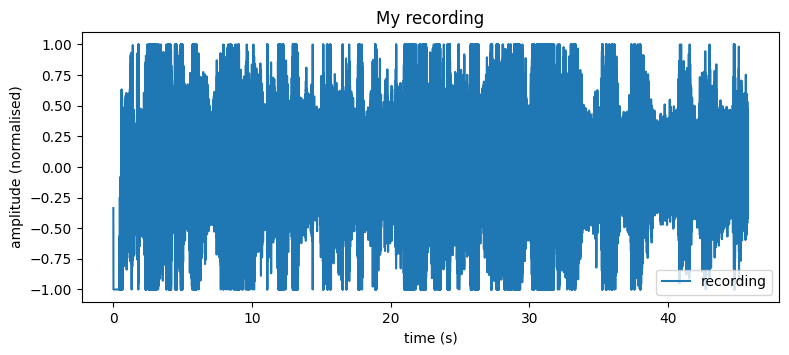

In [16]:
import os
fname = "my_voice.wav"            # change to your file name
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:                # stereo -> mono
        x = x.mean(axis=1)
    x = x / np.max(np.abs(x))     # normalise to [-1, 1]
else:                             # fallback test signal
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)
t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")
plt.plot(t, x, label="recording"); plt.xlabel("time (s)"); plt.ylabel("amplitude (normalised)")
plt.title("My recording"); plt.legend(); plt.show()
# To listen:  from IPython.display import Audio; Audio(x, rate=fs)

## Task 1.4 — Octave (optional)
`n = -5:10; stem(n, double(n>=0))` — differences: Octave indexes from 1, uses `%` for comments, `.^` for element-wise power, and needs `pkg load signal`.

## Task 1.5 — Repository and submission
```
git init COU07506-labs && cd COU07506-labs
git add COU07506_Week01_<RegNo>.ipynb
git commit -m "Week 1 notebook"
git remote add origin https://github.com/<you>/COU07506-labs.git
git push -u origin main
```

In [17]:
print("Sampling rate:", fs, "Hz")
print("Numbers for one minute, mono:", 60*fs)

Sampling rate: 44100 Hz
Numbers for one minute, mono: 2646000


## Analysis questions


1. Sampling rate and one minute of mono

The sampling rate of my recording is 44,100 Hz. One minute of mono audio needs 60 × 44,100 = 2,646,000 numbers, because each second contributes 44,100 samples. My recording is 45.74 s long and holds 2,017,047 samples (45.74 × 44,100), which matches the printed values.

If you want a bit more, add that at 16 bits per sample this is about 5.3 MB per minute.

2. Why a stem plot

A discrete-time signal x(n) is defined only at integer values of n, so there are no values between the samples. A stem plot shows each sample as an isolated point, which is true to the data. A continuous line would wrongly suggest the signal has values between samples.

3. a = 1.1 as an impulse response

For a = 1.1 the sequence h(n) = 1.1ⁿu(n) grows without bound, so the sum of |h(n)| is infinite. An impulse response like this would violate BIBO stability (bounded input, bounded output). Even a simple bounded input such as a unit step would produce an output that grows forever.

## AI-use statement
AI tools used: Claude (Anthropic)
Used for: setting up the notebook structure, explaining why cos(2πn/7.5)
is periodic with period 15, and helping record and convert my voice
file to WAV.
How I verified the output: I checked the repeats with np.allclose, compared
the printed sampling rate (44,100 Hz) and duration (45.74 s) with my
recording, and checked the stem plots against the expected shapes.
I confirm that I understand and can explain all submitted code.